## 🎢 Sales Forecasting

Purpose: Predict future sales using Machine Learning.

1.Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

2.Load Dataset

In [2]:
df = pd.read_csv("cleaned_sales_data.csv")

3.Convert Date

In [3]:
df["Date"] = pd.to_datetime(df["Date"])

4.Aggregate Monthly Revenue

In [22]:
monthly_sales = df.groupby(
    pd.Grouper(key="Date", freq="ME")
)["Revenue"].sum().reset_index()

monthly_sales.head()

,Date,Revenue
0,2021-01-31,106600
1,2021-02-28,105183
2,2021-03-31,46857
3,2021-04-30,73496
4,2021-05-31,61166


5.Create Month Number

In [23]:
monthly_sales["Month_Number"] = np.arange(len(monthly_sales))


6.Prepare Features

In [24]:
X = monthly_sales[["Month_Number"]]
y = monthly_sales["Revenue"]

7.Split Data

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

8.Train Model

In [26]:
model = LinearRegression()

model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[29.59]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Month_Number']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.685e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


9.Forecast Next 12 Months

In [27]:
future_months = np.arange(
    len(monthly_sales),
    len(monthly_sales)+12
).reshape(-1,1)

future_predictions = model.predict(future_months)

c:\Users\Somesh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


10.Evaluate Model

In [28]:
future_dates = pd.date_range(
    start=monthly_sales["Date"].max() + pd.offsets.MonthEnd(1),
    periods=12,
    freq="ME"
)

12.Visualize Forecast

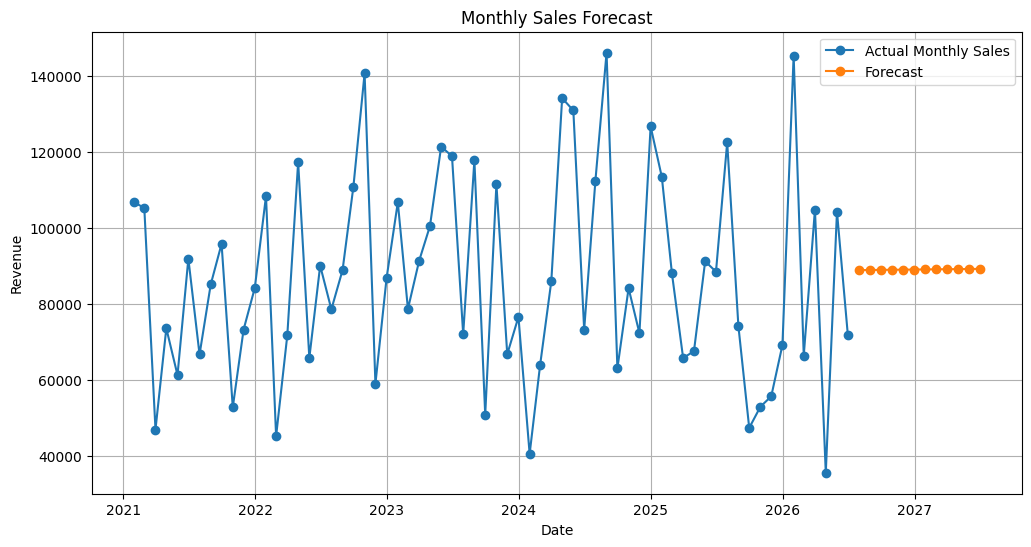

In [30]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Revenue"],
    marker="o",
    label="Actual Monthly Sales"
)

plt.plot(
    future_dates,
    future_predictions,
    marker="o",
    label="Forecast"
)

plt.title("Monthly Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)

plt.show()

13.Future Prediction

In [ ]:
forecast_table = pd.DataFrame({
    "Month": future_dates,
    "Predicted_Revenue": future_predictions
})

forecast_table